In [1]:
#Import des libraries
import dask.dataframe as dd
import pandas as pd
import plotly.express as px
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
import openpyxl
from openpyxl.styles import Font, Alignment, PatternFill, Border, Side
sns.set()

**Eape 1 : Traitement des données**

In [2]:
#Importation des données : Individus localisés au canton ou ville (2021) par l'INSEE : https://www.insee.fr/fr/statistiques/8268848?sommaire=8205966#consulter
dtypes = {
    "IRIS": "object",
    "AGEREV": "float64",  # ou int si sûr que ce sont des entiers
    "AGED": "float64",
    "IPONDI": "float64",
    'ACHLR': 'object',
       'AEMMR': 'object',
       'ANEMR': 'object',
       'APAF': 'object',
       'ASCEN': 'object',
       'CATL': 'object',
       'CHFL': 'object',
       'CMBL': 'object',
       'DNAI': 'object',
       'GARL': 'object',
       'HLML': 'object',
       'INFAM': 'object',
       'INPER': 'object',
       'IRAN': 'object',
       'LIENF': 'object',
       'LPRF': 'object',
       'LPRM': 'object',
       'NBPI': 'object',
       'NPERR': 'object',
       'NUMMI': 'object',
       'PCSL': 'object',
       'SANI': 'object',
       'SFM': 'object',
       'STOCD': 'object',
       'SURF': 'object',
       'TDM8': 'object',
       'TYPC': 'object',
       'TYPL': 'object',
       'TYPMC': 'object',
       'TYPMR': 'object',
       'VOIT': 'object'
}

data = dd.read_csv("FD_INDCVI_2022.csv",sep=";", usecols=["IRIS","AGEREV","AGED","IPONDI"], dtype=dtypes)

In [3]:
#On convertit tous les IRIS en chaînes de caractères par sécurité
#data["IRIS"] = data["IRIS"].astype(str)
#print(data["IRIS"])
#On test sur certaines variables et on affiche
#data2=data[(data["IRIS"] != "ZZZZZZZZZ") & (data["IRIS"] == "595121101") & (data["AGEREV"] <= 8)]
#print(len(data2))
#print(data2)

In [4]:
#Récupération des iris de roubaix
iris_roubaix = pd.read_csv("iris_roubaix.csv")

In [5]:
#On ne prend que les enfants (< 18 ans)
enfants_age_revolu = data[data["AGEREV"] < 18]
enfants_age_au_millesime = data[data["AGED"] < 18]

#Réinitialisation des index sur la nouvelle plage de données
enfants_age_revolu = enfants_age_revolu.reset_index(drop=True)
enfants_age_au_millesime = enfants_age_au_millesime.reset_index(drop=True)

In [6]:
#On ne prend que les enfants de Roubaix
enfants_roubaix_age_revolu = dd.merge(left=enfants_age_revolu, right=iris_roubaix, left_on="IRIS", right_on="IRIS")
enfants_roubaix_age_au_millesime = dd.merge(left=enfants_age_au_millesime, right=iris_roubaix, left_on="IRIS", right_on="IRIS")

Attention il faut pondérer chaque individu de l'échantillon par son poids IPONDI !

In [7]:
#Affichage du nombre d'enfants selon 2 critères 
#Attention les calculs sont réaliser depuis un poids d'individu donc ne sont pas exact au chiffre près
#print("Nombre d'enfants (âge révolu) : "+ str(sum(enfants_roubaix_age_revolu['IPONDI'])))
#print("Nombre d'enfants (âge au millésime) : "+ str(sum(enfants_roubaix_age_au_millesime['IPONDI'])))

In [8]:
#Tranformation de la colonne IPONDI en décimal
enfants_roubaix_age_revolu['IPONDI'] = enfants_roubaix_age_revolu['IPONDI'].astype(float)
enfants_roubaix_age_au_millesime['IPONDI'] = enfants_roubaix_age_au_millesime['IPONDI'].astype(float)
#Calcul du nombre total d'enfants
nb_enfant_rev=sum(enfants_roubaix_age_revolu['IPONDI'])
print("Nombre d'enfants (âge révolu) : "+ str(nb_enfant_rev))
nb_enfant_mil=sum(enfants_roubaix_age_au_millesime['IPONDI'])
print("Nombre d'enfants (âge au millésime) : "+ str(nb_enfant_mil))

Nombre d'enfants (âge révolu) : 29533.507111533676
Nombre d'enfants (âge au millésime) : 27992.112363854623


Âge révolu = nombre d'années entières depuis le jour de naissance 
 
Âge en différence de millésime = nombre d'années entières entre le jour de naissance et le 31 décembre de l'année du recensement

In [9]:
#Convertir les DataFrames Dask en DataFrames pandas
enfants_roubaix_age_revolu = enfants_roubaix_age_revolu.compute()
enfants_roubaix_age_au_millesime = enfants_roubaix_age_au_millesime.compute()

In [10]:
#Tableau final : IRIS, âge de l'enfant et poids de l'individu dans l'échantillon
#enfants_roubaix_age_revolu["IPONDI"] = round(enfants_roubaix_age_revolu["IPONDI"],0)
#enfants_roubaix_age_au_millesime["IPONDI"] = round(enfants_roubaix_age_au_millesime["IPONDI"],0)

enfants_roubaix_age_revolu = enfants_roubaix_age_revolu[["LIB_IRIS","AGEREV","IPONDI"]].groupby(["LIB_IRIS","AGEREV"]).sum()
enfants_roubaix_age_revolu = enfants_roubaix_age_revolu.reset_index(level=(0,1))

enfants_roubaix_age_au_millesime = enfants_roubaix_age_au_millesime[["LIB_IRIS","AGED","IPONDI"]].groupby(["LIB_IRIS","AGED"]).sum()
enfants_roubaix_age_au_millesime = enfants_roubaix_age_au_millesime.reset_index(level=(0,1))

In [11]:
#On exporte les résultats dans des fichiers Excel
df = pd.DataFrame({"Libellé de l'Iris":enfants_roubaix_age_revolu["LIB_IRIS"],"Âge révolu (en années)":enfants_roubaix_age_revolu['AGEREV'],"Nombre d'enfants":round(enfants_roubaix_age_revolu['IPONDI'],0)})
df.to_excel("Content/age_revolu_enfants_roubaix.xlsx", index=False)

df2 = pd.DataFrame({"Libellé de l'Iris":enfants_roubaix_age_au_millesime["LIB_IRIS"],"Âge millesime (en années)":enfants_roubaix_age_au_millesime['AGED'],"Nombre d'enfants":round(enfants_roubaix_age_au_millesime['IPONDI'],0)})
df2.to_excel("Content/age_diff_millesime_enfants_roubaix.xlsx", index=False)

#enfants_roubaix_age_revolu.to_csv("Content/age_revolu_enfants_roubaix.csv", index=False)
#enfants_roubaix_age_au_millesime.to_csv("Content/age_diff_millesime_enfants_roubaix.csv",index=False)

In [12]:
#enfants_roubaix = pd.read_csv("age_diff_millesime_enfants_roubaix.csv")
#enfants_roubaix_2 = pd.read_csv("age_revolu_enfants_roubaix.csv")

**Etape 2 : Représentations graphiques**

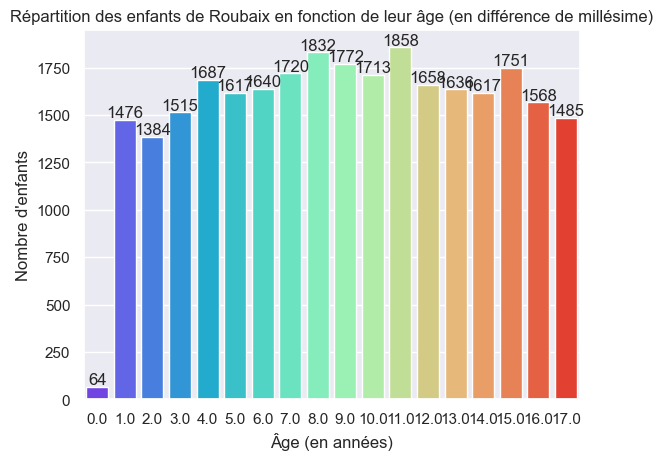

In [13]:
#Création et exportation du dataframe en un unique graphique
ages_au_millesime = sns.barplot(data=enfants_roubaix_age_au_millesime.groupby("AGED").sum().reset_index(level=0), x="AGED", y="IPONDI", palette="rainbow")
ages_au_millesime.set_xlabel("Âge (en années)")
ages_au_millesime.set_ylabel("Nombre d'enfants")
ages_au_millesime.set_title("Répartition des enfants de Roubaix en fonction de leur âge (en différence de millésime)")
for p in ages_au_millesime.patches:
    ages_au_millesime.annotate(format(p.get_height(), '.0f'),  # Affiche la valeur sans décimales
                      (p.get_x() + p.get_width() / 2., p.get_height()),  # Position au centre de la barre
                      ha='center', va='center', 
                      xytext=(0, 5),  # Décalage pour que le texte ne soit pas collé à la barre
                      textcoords='offset points')
plt.savefig("Graphiques/enfants_roubaix (diff_millésime).png")

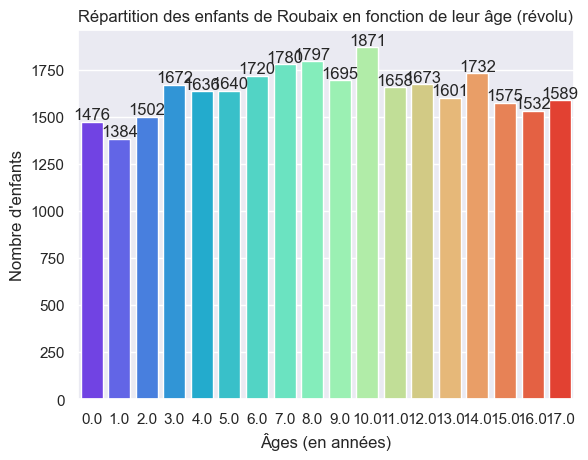

In [14]:
#Création et exportation du dataframe en un unique graphique
ages_revolus = sns.barplot(data=enfants_roubaix_age_revolu.groupby("AGEREV").sum().reset_index(level=0), x="AGEREV", y="IPONDI", palette="rainbow")
ages_revolus.set_xlabel("Âges (en années)")
ages_revolus.set_ylabel("Nombre d'enfants")
ages_revolus.set_title("Répartition des enfants de Roubaix en fonction de leur âge (révolu)")
for p in ages_revolus.patches:
    ages_revolus.annotate(format(p.get_height(), '.0f'),  # Affiche la valeur sans décimales
                      (p.get_x() + p.get_width() / 2., p.get_height()),  # Position au centre de la barre
                      ha='center', va='center', 
                      xytext=(0, 5),  # Décalage pour que le texte ne soit pas collé à la barre
                      textcoords='offset points')
plt.savefig("Graphiques/enfants_roubaix (révolu).png")

Pour chaque IRIS on créé le graphique de répartition des âges et on l'enregistre

In [15]:
#Création et exportation des dataframes regroupés selon la zone (Iris) en plusieurs graphiques
for iris in tqdm(enfants_roubaix_age_au_millesime['LIB_IRIS'].unique()):
  est_dans_iris = enfants_roubaix_age_au_millesime["LIB_IRIS"] == iris

  plot = sns.barplot(data=enfants_roubaix_age_au_millesime[est_dans_iris].groupby("AGED").sum().reset_index(level=0), x="AGED", y="IPONDI", palette="rainbow")
  plot.set_xlabel("Âge (en années)")
  plot.set_ylabel("Nombre d'enfants")
  plot.set_title("Répartition des enfants en fonction de leur âge en différence de millésime ("+iris+")")
  # Ajout des étiquettes de valeurs au-dessus de chaque barre
  for p in plot.patches:
    plot.annotate(format(p.get_height(), '.0f'),  # Affiche la valeur sans décimales
                      (p.get_x() + p.get_width() / 2., p.get_height()),  # Position au centre de la barre
                      ha='center', va='center', 
                      xytext=(0, 5),  # Décalage pour que le texte ne soit pas collé à la barre
                      textcoords='offset points')
    
  # Sauvegarde du graphique
  plt.savefig("Graphiques/Diff millésime/"+iris+" (diff_millésime).png")
  plt.clf()  # Pour éviter que les graphiques se superposent dans la boucle

<Figure size 640x480 with 0 Axes>

In [16]:
#Création et exportation des dataframes regroupés selon la zone (Iris) en plusieurs graphiques
for iris in tqdm(enfants_roubaix_age_revolu['LIB_IRIS'].unique()):
  est_dans_iris = enfants_roubaix_age_revolu["LIB_IRIS"] == iris

  plot = sns.barplot(data=enfants_roubaix_age_revolu[est_dans_iris].groupby("AGEREV").sum().reset_index(level=0), x="AGEREV", y="IPONDI", palette="rainbow")
  plot.set_xlabel("Âge (en années)")
  plot.set_ylabel("Nombre d'enfants")
  plot.set_title("Répartition des enfants en fonction de leur âge révolu ("+iris+")")
  # Ajout des étiquettes de valeurs au-dessus de chaque barre
  for p in plot.patches:
    plot.annotate(format(p.get_height(), '.0f'),  # Affiche la valeur sans décimales
                      (p.get_x() + p.get_width() / 2., p.get_height()),  # Position au centre de la barre
                      ha='center', va='center', 
                      xytext=(0, 5),  # Décalage pour que le texte ne soit pas collé à la barre
                      textcoords='offset points')
  plt.savefig("Graphiques/Âge révolu/"+iris+"(révolu).png")
  plt.clf()  # Pour éviter que les graphiques se superposent dans la boucle

<Figure size 640x480 with 0 Axes>

In [17]:
#Affichage des données pour voir la cohérence
print(enfants_roubaix_age_revolu)
print(enfants_roubaix_age_au_millesime)

       LIB_IRIS  AGEREV     IPONDI
0     Alma Nord     0.0   9.646314
1     Alma Nord     1.0  17.451311
2     Alma Nord     2.0   9.409224
3     Alma Nord     3.0  15.256883
4     Alma Nord     4.0  38.857378
..          ...     ...        ...
677  Épeule Sud    13.0  16.736434
678  Épeule Sud    14.0  38.081816
679  Épeule Sud    15.0  41.895412
680  Épeule Sud    16.0  14.837515
681  Épeule Sud    17.0  29.970206

[682 rows x 3 columns]
       LIB_IRIS  AGED     IPONDI
0     Alma Nord   1.0   9.646314
1     Alma Nord   2.0  17.451311
2     Alma Nord   3.0   9.409224
3     Alma Nord   4.0  18.725181
4     Alma Nord   5.0  35.389080
..          ...   ...        ...
651  Épeule Sud  13.0   9.814575
652  Épeule Sud  14.0  22.445593
653  Épeule Sud  15.0  36.478073
654  Épeule Sud  16.0  37.789996
655  Épeule Sud  17.0  14.837515

[656 rows x 3 columns]


**Etape 3 : Tableaux de contigence**

In [18]:
#Test avec les données 
test = enfants_roubaix_age_au_millesime.copy()[enfants_roubaix_age_au_millesime['LIB_IRIS']=='Sartel']
print(test)
pd.DataFrame({"Âge (en années)":test['AGED'],"Nombre d'enfants":round(test['IPONDI'],0)})

    LIB_IRIS  AGED     IPONDI
518   Sartel   0.0   3.369514
519   Sartel   1.0  30.214602
520   Sartel   2.0  12.048852
521   Sartel   3.0  18.448002
522   Sartel   4.0  26.242562
523   Sartel   5.0  13.027054
524   Sartel   6.0  35.602455
525   Sartel   7.0  18.776915
526   Sartel   8.0  23.145047
527   Sartel   9.0  27.529963
528   Sartel  10.0  29.135426
529   Sartel  11.0  18.134973
530   Sartel  12.0  21.408745
531   Sartel  13.0  29.174141
532   Sartel  14.0  26.138885
533   Sartel  15.0  26.448084
534   Sartel  16.0  28.408808
535   Sartel  17.0  32.818185


,Âge (en années),Nombre d'enfants
518,0.0,3.0
519,1.0,30.0
520,2.0,12.0
521,3.0,18.0
522,4.0,26.0
523,5.0,13.0
524,6.0,36.0
525,7.0,19.0
526,8.0,23.0
527,9.0,28.0


In [19]:
#Exportation des dataframes regroupés selon la zone (Iris) en plusieurs fichiers excel (.xlsx)
for iris in tqdm(enfants_roubaix_age_revolu['LIB_IRIS'].unique()):
  table = enfants_roubaix_age_revolu.copy()[enfants_roubaix_age_revolu['LIB_IRIS']==iris]
  df = pd.DataFrame({"Âge (en années)":table['AGEREV'],"Nombre d'enfants":round(table['IPONDI'],0)})
  df.to_excel("Content/Âge révolu/"+iris+" (révolu).xlsx",index=False,sheet_name=iris)

100%|██████████| 38/38 [00:01<00:00, 28.07it/s]


In [20]:
#Exportation des dataframes regroupés selon la zone (Iris) en plusieurs fichiers excel (.xlsx)
for iris in tqdm(enfants_roubaix_age_au_millesime['LIB_IRIS'].unique()):
  table = enfants_roubaix_age_au_millesime.copy()[enfants_roubaix_age_au_millesime['LIB_IRIS']==iris]
  df = pd.DataFrame({"Âge (en années)":table['AGED'],"Nombre d'enfants":round(table['IPONDI'],0)})
  df.to_excel("Content/Diff millésime/"+iris+" (diff millésime).xlsx",index=False,sheet_name=iris)

100%|██████████| 38/38 [00:01<00:00, 29.18it/s]


In [21]:
# Charger le fichier Excel
file_path = "Content/age_revolu_enfants_roubaix.xlsx"        # Modification à apporter selon l'endroit où est contenu le fichier Excel

# Charger le fichier avec pandas
df = pd.read_excel(file_path)

# Afficher les 5 premières lignes pour vérifier le contenu du fichier
#print(df.head())

# Utiliser pivot_table pour transformer 'Âge révolu (en années)' en plusieurs colonnes et remplir les intersections avec les valeurs
pivot_df = df.pivot_table(index="Libellé de l'Iris", columns="Âge révolu (en années)", values="Nombre d'enfants", aggfunc='sum', fill_value=0)

# Afficher le DataFrame pivoté pour vérifier
#print(pivot_df)

# Sauvegarder ce DataFrame pivoté dans un nouveau fichier Excel (facultatif), permet de visualiser notre tableau de sortie
#pivot_df.to_excel("Content/tab_age_revolu_enfants_roubaix.xlsx", engine='openpyxl')

df_csv = pd.read_csv('Périmètres_MAS.csv')
df_csv = df_csv.drop(["IRIS","id_sig"],axis=1)
df_csv = df_csv.rename(columns = {"Libellé_IRIS": "Libellé de l'Iris","Centre_Social": "Centres sociaux", "Crèche": "Crèches", "Périmètre_NPNRU": "Périmètres NPNRU", "CDV": "Contrats de Ville (CDV)",
                                    "Cité_Educative": "Cités éducatives", "Quartiers_SIG": "Quartiers SIG (Grands quartiers)", "Quartier": "Mairies de qartiers",})
#print(df_csv.head())
#print(df_csv.columns)
# Fusionner les deux DataFrames sur la colonne 'Libellé de l'Iris'
df_merged = pd.merge(df_csv, pivot_df, on="Libellé de l'Iris", how='right')  # 'right' permet de garder toutes les lignes de df_excel
df_merged = df_merged.rename(columns = {0: "Age : 0", 1: "Age : 1", 2: "Age : 2", 3: "Age : 3", 4: "Age : 4", 5: "Age : 5", 6: "Age : 6", 7: "Age : 7", 8: "Age : 8", 9: "Age : 9", 
                                    10: "Age : 10", 11: "Age : 11", 12: "Age : 12", 13: "Age : 13", 14: "Age : 14", 15: "Age : 15", 16: "Age : 16", 17: "Age : 17"})
df_merged["Libellé de l'Iris"] = df_merged["Libellé de l'Iris"].str.upper()
#print(df_csv.head())
#print(df_merged.columns)

# Identifiez la position de la colonne 'Libellé de l'Iris'
columns = list(df_merged.columns)
libelle_index = columns.index("Libellé de l'Iris")

# Si vous voulez déplacer toutes les colonnes du CSV avant les colonnes 'Mairies de qartiers' et 'Libellé de l'Iris'
new_order = [col for col in df_csv.columns if col != "Libellé de l'Iris" and col != "Mairies de qartiers"] + ["Mairies de qartiers"] +["Libellé de l'Iris"] + [col for col in columns if col not in df_csv.columns]

# Réorganiser les colonnes
df_merged = df_merged[new_order]
print(df_merged.columns)

# Ajouter une colonne 'TOTAL 0-17' qui est la somme des valeurs de chaque ligne
# On ne sélectionne que les cases nombre (là où il y a une valeur)
df_merged['TOTAL 0-17'] = df_merged.select_dtypes(include=['number']).sum(axis=1)

# Exporter vers un fichier Excel
df_merged.to_excel('Content/tab_mas_age_revolu_enfants_roubaix.xlsx', index=False)

# Inspection les colonnes
for col in df_merged.columns:
    print(col)


Index(['Centres sociaux', 'Crèches', 'Périmètres NPNRU',
       'Contrats de Ville (CDV)', 'Cités éducatives',
       'Quartiers SIG (Grands quartiers)', 'Mairies de qartiers',
       'Libellé de l'Iris', 'Age : 0', 'Age : 1', 'Age : 2', 'Age : 3',
       'Age : 4', 'Age : 5', 'Age : 6', 'Age : 7', 'Age : 8', 'Age : 9',
       'Age : 10', 'Age : 11', 'Age : 12', 'Age : 13', 'Age : 14', 'Age : 15',
       'Age : 16', 'Age : 17'],
      dtype='object')
Centres sociaux
Crèches
Périmètres NPNRU
Contrats de Ville (CDV)
Cités éducatives
Quartiers SIG (Grands quartiers)
Mairies de qartiers
Libellé de l'Iris
Age : 0
Age : 1
Age : 2
Age : 3
Age : 4
Age : 5
Age : 6
Age : 7
Age : 8
Age : 9
Age : 10
Age : 11
Age : 12
Age : 13
Age : 14
Age : 15
Age : 16
Age : 17
TOTAL 0-17


In [22]:
# Mise en forme de l'excel

# Charger le fichier Excel existant
wb = openpyxl.load_workbook('Content/tab_mas_age_revolu_enfants_roubaix.xlsx')
ws = wb.active

# 1. Insérer une ligne vide au début pour laisser la ligne 1 vide
ws.insert_rows(1, amount=1)  # Décale tout le contenu vers le bas d'une ligne

# 2. Déplacer les titres (ligne 2) vers la ligne 2
for col_idx, cell in enumerate(ws[2], start=1):
    ws.cell(row=2, column=col_idx, value=cell.value)

# 3. Vider la première ligne (ligne 1) si vous le souhaitez
for col_idx in range(1, len(ws[2]) + 1):  # effacer les valeurs de la première ligne
    ws.cell(row=1, column=col_idx, value=None)

# 4. Mettre "Total" dans la cellule H1
ws.cell(row=1, column=8, value="Total")

# 5. Initialiser une variable gras
bold_font = Font(bold=True)

# 6. Calculer les sous-totaux pour les colonnes à partir de I (colonne 9) avec la somme (SUM)
for col_idx in range(9, ws.max_column + 1):  # Commencer à la colonne I (colonne 9)
    last_row = ws.max_row
    # Utiliser la fonction SUM pour la colonne correspondante (commence à la ligne 3)
    ws.cell(row=1, column=col_idx, value=f"=SUBTOTAL(9,{get_column_letter(col_idx)}3:{get_column_letter(col_idx)}{last_row})")
    ws.cell(row=1, column=col_idx).font = bold_font

# 7. Récupérer les données du DataFrame et les écrire à partir de la ligne 3
for row_idx, row in enumerate(df_merged.values, start=3):  # start=3 pour commencer à la ligne 3
    for col_idx, value in enumerate(row, start=1):
        ws.cell(row=row_idx, column=col_idx, value=value)

# 8. Réinitialiser la ligne 2 à un format normal (sans gras)
for col_idx in range(1, len(ws[2]) + 1):
    ws.cell(row=2, column=col_idx).font = Font(bold=False)  # Assurez-vous que la ligne 2 n'est pas en gras

# 9. Appliquer le gras à toutes les lignes de A à H (y compris la ligne 1)
for row_idx in range(1, ws.max_row + 1):  # Commencer à la ligne 1 et aller jusqu'à la dernière ligne
    for col_idx in range(1, 9):  # de la colonne A (1) à H (8)
        ws.cell(row=row_idx, column=col_idx).font = bold_font

# 10. Appliquer un format spécifique à la ligne 2 : hauteur, alignement, retour à la ligne
ws.row_dimensions[2].height = 80  # Hauteur de la ligne 2
# Définir la largeur des colonnes, en se basant sur les titres de la ligne 2
for col_idx in range(1, len(ws[2]) + 1):
    col_letter = openpyxl.utils.get_column_letter(col_idx)
    if ws.cell(row=2, column=col_idx).value == "Libellé de l'Iris":
        ws.column_dimensions[col_letter].width = 24  # Largeur spécifique pour la colonne "Libellé de l'Iris"
    else:
        ws.column_dimensions[col_letter].width = 15  # Largeur par défaut pour les autres colonnes


# Appliquer l'alignement centré et le retour à la ligne automatique sur toutes les cellules de la ligne 1 et 2

for col_idx in range(1, len(ws[3]) + 1):
    cell = ws.cell(row=1, column=col_idx)
    cell.alignment = Alignment(horizontal="center")
    cell.font = Font(color="00B050", bold=True)
    cell = ws.cell(row=2, column=col_idx)
    cell.alignment = Alignment(horizontal="center", vertical="center", wrap_text=True)  # Centrer et retour à la ligne

# Récupérer l'index de la dernière colonne de la feuille Excel
last_col_idx = ws.max_column

# Définir une bordure grise (tout autour de la cellule)
gray_border = Border(
    left=Side(border_style="thin", color="BFBFBF"),  # Bordure grise à gauche
    right=Side(border_style="thin", color="BFBFBF"),  # Bordure grise à droite
    top=Side(border_style="thin", color="BFBFBF"),  # Bordure grise en haut
    bottom=Side(border_style="thin", color="BFBFBF")  # Bordure grise en bas
)

# Appliquer les couleurs de fond en fonction de la ligne et de la colonne
for row in ws.iter_rows(min_row=1, max_row=ws.max_row, min_col=1, max_col=last_col_idx):
    for cell in row:
        # Assurez-vous que vous travaillez avec la ligne correcte (1 pour les titres, 2 pour les sous-titres, etc.)
        if cell.row == 1:
            # Appliquer une couleur verte sur les colonnes de 7 à 24
            if 8 <= cell.column <= ws.max_column:
                cell.fill = PatternFill(start_color="EBF1DE", end_color="EBF1DE", fill_type="solid")  # Fond vert
        elif cell.row == 2:
            # Appliquer une couleur grise sur les premières colonnes et bleue sur les autres
            if cell.column <= 8:
                cell.fill = PatternFill(start_color="BFBFBF", end_color="BFBFBF", fill_type="solid")  # Fond gris
            else:
                cell.fill = PatternFill(start_color="91DEFF", end_color="91DEFF", fill_type="solid")  # Fond bleu
        else:
            # Appliquer une couleur grise pour les autres lignes
            if cell.column <= 8:
                cell.fill = PatternFill(start_color="F2F2F2", end_color="F2F2F2", fill_type="solid")  # Fond gris
        cell.border = gray_border
        
# 11. Sauvegarder le fichier Excel modifié
wb.save('Content/tab_mas_age_revolu_enfants_roubaix_deplace.xlsx')

NameError: name 'get_column_letter' is not defined